In [ ]:
import pandas as pd
import requests
from google.colab import userdata

API_KEY = userdata.get('API_KEY')
headers = {'Authorization': f'Bearer {API_KEY}'}
base_url = 'https://apidadosabertos.saude.gov.br/vigilancia-e-meio-ambiente/sistema-de-informacao-sobre-mortalidade'

CAMPOS = ["dtobito", "idade", "sexo", "racacor", "esc2010", "codmunres", "lococor", "causabas"]
COD_ARARANGUA = "420140"  

LIMIT = 1000
MAX_PAGINAS = 800  
!wget -q -O CID-10-CATEGORIAS.CSV "https://raw.githubusercontent.com/cleytonferrari/CidDataSus/master/CIDImport/Repositorio/Resources/CID-10-CATEGORIAS.CSV"
CAMINHO_CID10 = "CID-10-CATEGORIAS.CSV"

cid10 = pd.read_csv(CAMINHO_CID10, sep=";", encoding="latin1")
cid10["CAT"] = cid10["CAT"].astype(str).str.strip().str.upper()

# Dicionario CAT (3 caracteres, ex: "A00") -> descricao por extenso
MAPA_CID10 = dict(zip(cid10["CAT"], cid10["DESCRICAO"]))

def decodifica_causabas(codigo):
    """CAUSABAS normalmente vem com 4 caracteres (categoria + subcategoria,
    ex: 'A419'). A tabela CID-10-CATEGORIAS traz a descricao apenas no nivel
    de categoria (3 caracteres, ex: 'A41'), entao usamos os 3 primeiros
    caracteres do codigo para localizar a doenca."""
    if pd.isna(codigo) or str(codigo).strip() == "":
        return None
    cod = str(codigo).strip().upper()
    cat = cod[:3]
    return MAPA_CID10.get(cat, f"Desconhecido ({cod})")


todos_registros = []
offset = 0

for pagina in range(MAX_PAGINAS):
    params = {'limit': LIMIT, 'offset': offset}
    resp = requests.get(base_url, headers=headers, params=params)
    resp.raise_for_status()
    dados = resp.json().get('sim', [])

    if not dados:
        print(f"Sem mais dados a partir do offset {offset}. Encerrando busca.")
        break

    todos_registros.extend(dados)
    offset += LIMIT
    print(f"Pagina {pagina + 1}: offset {offset - LIMIT}, {len(dados)} registros (total acumulado: {len(todos_registros)})")

df = pd.DataFrame(todos_registros)
df = df[CAMPOS]
df.columns = [c.upper() for c in df.columns]


# 2) Decodificacao dos campos conforme o Dicionario de Dados do SIM (06/2025)


def decodifica_idade(valor):
    """IDADE = 1 digito de unidade + 2 digitos de quantidade.
    1-minuto, 2-hora, 3-mes, 4-ano, 5-mais de 100 anos, 9-ignorado."""
    if pd.isna(valor) or valor in (None, ""):
        return None
    v = str(valor).zfill(3)
    unidade, qtd = v[0], v[1:]
    mapa_unidade = {
        "1": "minuto(s)",
        "2": "hora(s)",
        "3": "mes(es)",
        "4": "ano(s)",
        "5": "ano(s) (100+)",
        "9": "idade ignorada",
    }
    if unidade == "9":
        return "Ignorado"
    return f"{int(qtd)} {mapa_unidade.get(unidade, 'unidade desconhecida')}"

def decodifica_dtobito(valor):
    """DTOBITO no padrao ddmmaaaa (as vezes sem zero a esquerda)."""
    if pd.isna(valor) or valor in (None, ""):
        return None
    v = str(valor).zfill(8)
    try:
        return pd.to_datetime(v, format="%d%m%Y").strftime("%d/%m/%Y")
    except ValueError:
        return None

MAPA_SEXO = {"1": "Masculino", "2": "Feminino", "0": "Ignorado", "9": "Ignorado",
             "M": "Masculino", "F": "Feminino", "I": "Ignorado"}

MAPA_RACACOR = {"1": "Branca", "2": "Preta", "3": "Amarela", "4": "Parda", "5": "Indigena"}

MAPA_ESC2010 = {
    "0": "Sem escolaridade",
    "1": "Fundamental I (1a a 4a serie)",
    "2": "Fundamental II (5a a 8a serie)",
    "3": "Medio (antigo 2o Grau)",
    "4": "Superior incompleto",
    "5": "Superior completo",
    "9": "Ignorado",
}

MAPA_LOCOCOR = {
    "1": "Hospital",
    "2": "Outros estabelecimentos de saude",
    "3": "Domicilio",
    "4": "Via publica",
    "5": "Outros",
    "6": "Aldeia indigena",
    "9": "Ignorado",
}

df["DTOBITO"] = df["DTOBITO"].apply(decodifica_dtobito)
df["IDADE"] = df["IDADE"].apply(decodifica_idade)
df["SEXO"] = df["SEXO"].map(MAPA_SEXO).fillna(df["SEXO"])
df["RACACOR"] = df["RACACOR"].map(MAPA_RACACOR).fillna(df["RACACOR"])
df["ESC2010"] = df["ESC2010"].map(MAPA_ESC2010).fillna(df["ESC2010"])
df["LOCOCOR"] = df["LOCOCOR"].map(MAPA_LOCOCOR).fillna(df["LOCOCOR"])

df["CAUSABAS_DESC"] = df["CAUSABAS"].apply(decodifica_causabas)


# 3) Filtro por Araranguá

df_ararangua = df[df["CODMUNRES"].astype(str).str.zfill(6) == COD_ARARANGUA].reset_index(drop=True)

print(f"\nTotal de registros verificados: {len(df)}")
print(f"Registros de Araranguá encontrados: {len(df_ararangua)}")
df_ararangua

In [ ]:
!pip install gdown -q

import gdown
import pandas as pd

file_id = '1MxWxvZVucgj8ZxFSl3p8N2PscCqQBw-i'
output = 'sim_sc_processado.csv'

gdown.download(id=file_id, output=output, quiet=False)

CAMPOS = ["DTOBITO", "IDADE", "SEXO", "RACACOR", "ESC2010", "CODMUNRES", "LOCOCOR", "CAUSABAS"]
COD_ARARANGUA = "420140"  # codigo IBGE (6 digitos) do municipio de Araranguá/SC

blocos = []
total_lido = 0
for bloco in pd.read_csv(output, sep=",", encoding="utf-8-sig", usecols=CAMPOS,
                          dtype=str, chunksize=200_000):
    total_lido += len(bloco)
    blocos.append(bloco[bloco["CODMUNRES"].astype(str).str[:6] == COD_ARARANGUA])

df_ararangua = pd.concat(blocos, ignore_index=True)
del blocos



def decodifica_idade(valor):
    """IDADE = 1 digito de unidade + 2 digitos de quantidade.
    1-minuto, 2-hora, 3-mes, 4-ano, 5-mais de 100 anos, 9-ignorado."""
    if pd.isna(valor) or valor in (None, ""):
        return None
    v = str(valor).zfill(3)
    unidade, qtd = v[0], v[1:]
    mapa_unidade = {
        "1": "minuto(s)",
        "2": "hora(s)",
        "3": "mes(es)",
        "4": "ano(s)",
        "5": "ano(s) (100+)",
        "9": "idade ignorada",
    }
    if unidade == "9":
        return "Ignorado"
    return f"{int(qtd)} {mapa_unidade.get(unidade, 'unidade desconhecida')}"

MAPA_ESC2010 = {
    "0": "Sem escolaridade",
    "1": "Fundamental I (1a a 4a serie)",
    "2": "Fundamental II (5a a 8a serie)",
    "3": "Medio (antigo 2o Grau)",
    "4": "Superior incompleto",
    "5": "Superior completo",
    "9": "Ignorado",
}

# Tabela oficial de categorias da CID-10 (mesma fonte da célula da API)
!wget -q -O CID-10-CATEGORIAS.CSV "https://raw.githubusercontent.com/cleytonferrari/CidDataSus/master/CIDImport/Repositorio/Resources/CID-10-CATEGORIAS.CSV"
cid10 = pd.read_csv("CID-10-CATEGORIAS.CSV", sep=";", encoding="latin1")
cid10["CAT"] = cid10["CAT"].astype(str).str.strip().str.upper()
MAPA_CID10 = dict(zip(cid10["CAT"], cid10["DESCRICAO"]))

def decodifica_causabas(codigo):
    if pd.isna(codigo) or str(codigo).strip() == "":
        return None
    cod = str(codigo).strip().upper()
    cat = cod[:3]
    return MAPA_CID10.get(cat, f"Desconhecido ({cod})")

df_ararangua["DTOBITO"] = pd.to_datetime(df_ararangua["DTOBITO"], errors="coerce").dt.strftime("%d/%m/%Y")
df_ararangua["IDADE"] = df_ararangua["IDADE"].apply(decodifica_idade)
df_ararangua["ESC2010"] = df_ararangua["ESC2010"].map(MAPA_ESC2010).fillna(df_ararangua["ESC2010"])
df_ararangua["CAUSABAS_DESC"] = df_ararangua["CAUSABAS"].apply(decodifica_causabas)

print(f"Total de registros verificados: {total_lido}")
print(f"Registros de Araranguá encontrados: {len(df_ararangua)}")
df_ararangua


Downloading...
From (original): https://drive.google.com/uc?id=1MxWxvZVucgj8ZxFSl3p8N2PscCqQBw-i
From (redirected): https://drive.google.com/uc?id=1MxWxvZVucgj8ZxFSl3p8N2PscCqQBw-i&confirm=t&uuid=aa95f1ca-6d46-498c-8574-a3b1e68e07f6
To: /content/sim_sc_processado.csv
100%|██████████| 457M/457M [00:05<00:00, 77.8MB/s]


Total de registros verificados: 1502195
Registros de Araranguá encontrados: 15608


,DTOBITO,IDADE,SEXO,RACACOR,CODMUNRES,LOCOCOR,CAUSABAS,ESC2010,CAUSABAS_DESC
0,30/08/2000,45 ano(s),Masculino,Branca,4201406,Via publica,V892,NaN,Acidente com um veículo a motor ou não-motoriz...
1,18/08/2000,35 ano(s),Masculino,Branca,4201406,Hospital,V892,NaN,Acidente com um veículo a motor ou não-motoriz...
2,02/01/2000,79 ano(s),Masculino,NaN,4201406,Hospital,I64,NaN,"Acidente vascular cerebral, não especificado c..."
3,01/01/2000,17 ano(s),Feminino,Branca,4201406,Hospital,O249,NaN,Diabetes mellitus na gravidez
4,21/02/2000,60 ano(s),Masculino,Branca,4201406,Via publica,V645,NaN,Ocupante de um veículo de transporte pesado tr...
...,...,...,...,...,...,...,...,...,...
15603,14/07/1999,33 ano(s),Feminino,Branca,4201406,Hospital,K088,NaN,Outros transtornos dos dentes e de suas estrut...
15604,21/06/1999,61 ano(s),Feminino,Branca,4201406,NaN,A419,NaN,Outras septicemias
15605,24/09/1999,13 ano(s),Feminino,Branca,4201406,Hospital,C719,NaN,Neoplasia maligna do encéfalo
15606,08/12/1999,62 ano(s),Masculino,Branca,4201406,Hospital,E142,NaN,Diabetes mellitus não especificado


Total de óbitos: 15608


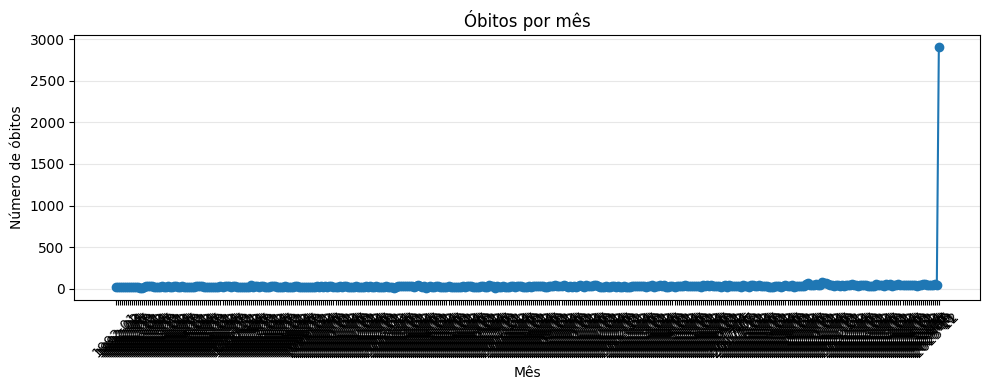

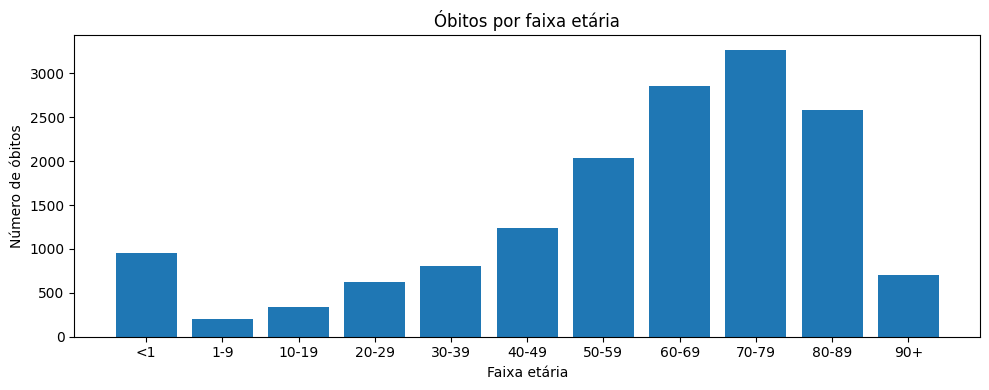

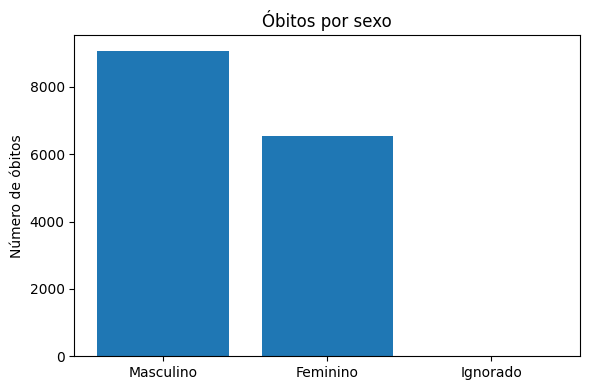

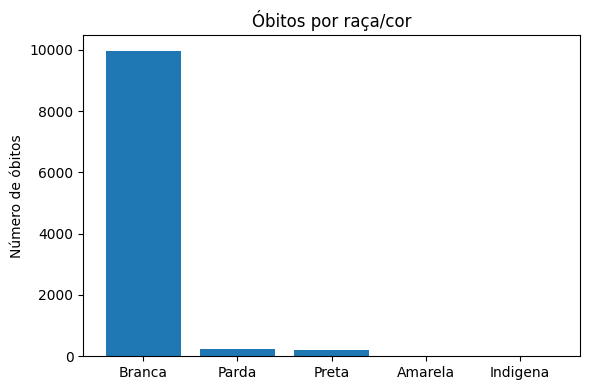

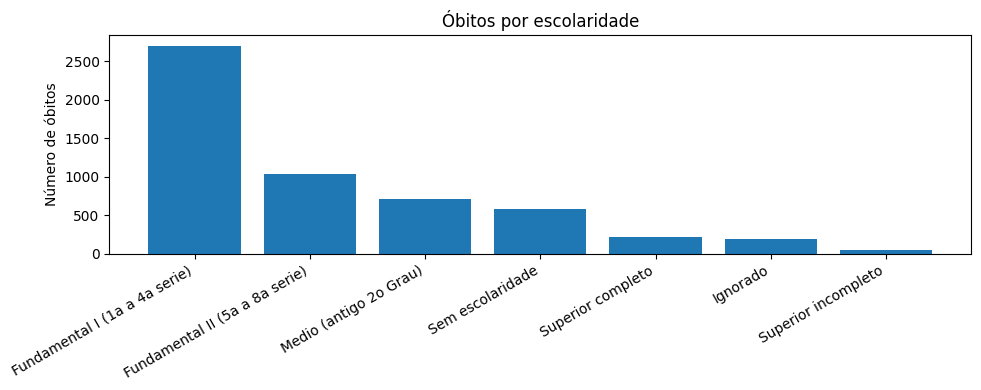

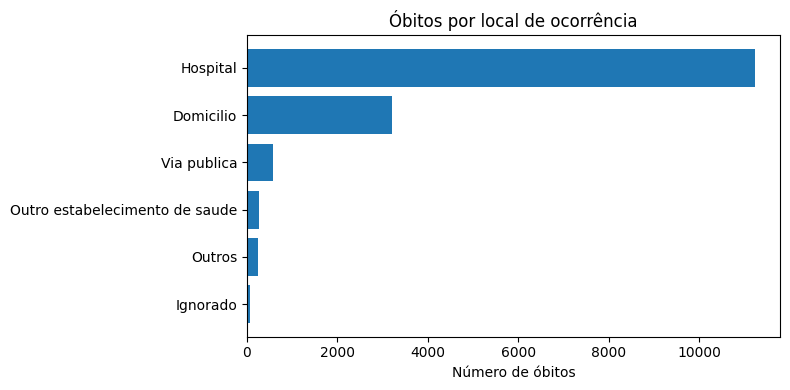

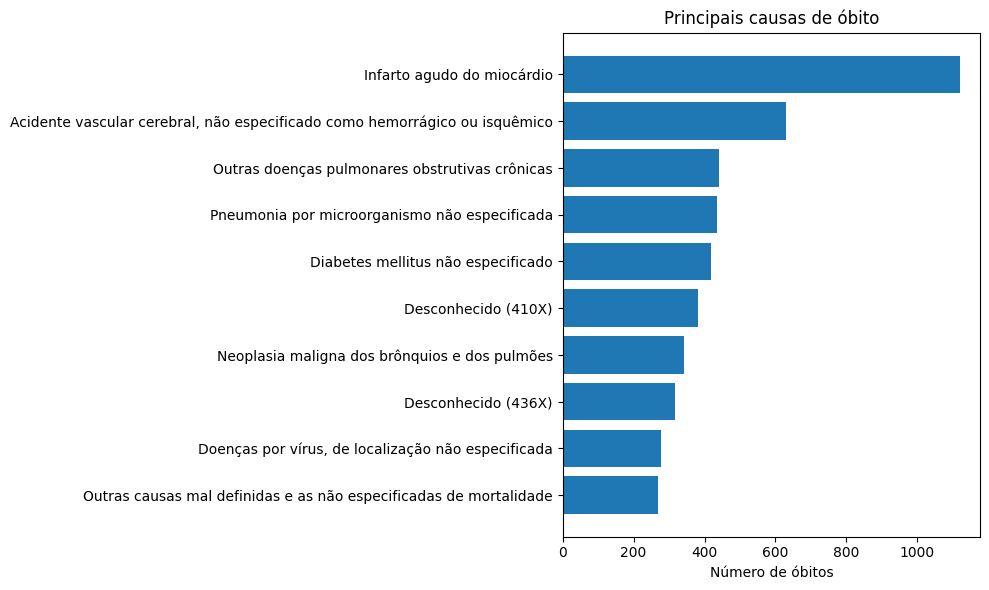

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


df = df_ararangua

# ---------------------------------------------------------------------------
# 2) Prepara colunas auxiliares
# ---------------------------------------------------------------------------
df["DTOBITO_DT"] = pd.to_datetime(df["DTOBITO"], format="%d/%m/%Y")
df["ANOMES"] = df["DTOBITO_DT"].dt.to_period("M").astype(str)

def idade_em_anos(valor):
    """Converte '60 ano(s)' -> 60. Para meses/horas/minutos, considera menor
    que 1 ano (retorna 0)."""
    if "ano(s)" in str(valor):
        try:
            return int(str(valor).split(" ")[0])
        except ValueError:
            return None
    return 0

df["IDADE_ANOS"] = df["IDADE"].apply(idade_em_anos)

faixas = [0, 1, 10, 20, 30, 40, 50, 60, 70, 80, 90, 200]
rotulos_faixas = ["<1", "1-9", "10-19", "20-29", "30-39", "40-49",
                   "50-59", "60-69", "70-79", "80-89", "90+"]
df["FAIXA_ETARIA"] = pd.cut(df["IDADE_ANOS"], bins=faixas, labels=rotulos_faixas, right=False)

obitos_por_mes = df.groupby("ANOMES").size()

print(f"Total de óbitos: {len(df)}")

plt.figure(figsize=(10, 4))
plt.plot(obitos_por_mes.index, obitos_por_mes.values, marker="o")
plt.title("Óbitos por mês")
plt.xlabel("Mês")
plt.ylabel("Número de óbitos")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


obitos_por_faixa = df["FAIXA_ETARIA"].value_counts().reindex(rotulos_faixas)

plt.figure(figsize=(10, 4))
plt.bar(obitos_por_faixa.index.astype(str), obitos_por_faixa.values)
plt.title("Óbitos por faixa etária")
plt.xlabel("Faixa etária")
plt.ylabel("Número de óbitos")
plt.tight_layout()
plt.show()

obitos_por_sexo = df["SEXO"].value_counts()

plt.figure(figsize=(6, 4))
plt.bar(obitos_por_sexo.index, obitos_por_sexo.values)
plt.title("Óbitos por sexo")
plt.ylabel("Número de óbitos")
plt.tight_layout()
plt.show()

obitos_por_raca = df["RACACOR"].value_counts()

plt.figure(figsize=(6, 4))
plt.bar(obitos_por_raca.index, obitos_por_raca.values)
plt.title("Óbitos por raça/cor")
plt.ylabel("Número de óbitos")
plt.tight_layout()
plt.show()

obitos_por_esc = df["ESC2010"].value_counts()

plt.figure(figsize=(10, 4))
plt.bar(obitos_por_esc.index, obitos_por_esc.values)
plt.title("Óbitos por escolaridade")
plt.ylabel("Número de óbitos")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


obitos_por_local = df["LOCOCOR"].value_counts()

plt.figure(figsize=(8, 4))
plt.barh(obitos_por_local.index, obitos_por_local.values)
plt.title("Óbitos por local de ocorrência")
plt.xlabel("Número de óbitos")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

top_causas = df["CAUSABAS_DESC"].value_counts().head(10)

plt.figure(figsize=(10, 6))
plt.barh(top_causas.index, top_causas.values)
plt.title("Principais causas de óbito")
plt.xlabel("Número de óbitos")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
!pip install gdown -q

import gdown
import pandas as pd

file_id = '1MxWxvZVucgj8ZxFSl3p8N2PscCqQBw-i'
output = 'sim_sc_processado.csv'
gdown.download(id=file_id, output=output, quiet=False)

CAMPOS = ["DTOBITO", "IDADE", "SEXO", "RACACOR", "ESC2010", "CODMUNRES", "LOCOCOR", "CAUSABAS"]
COD_ARARANGUA = "420140"  # codigo IBGE (6 digitos) do municipio de Araranguá/SC
ANO_INICIO, ANO_FIM = 2024, 2025  # <- ajuste o período aqui

# Leitura em blocos (a base tem ~1,5 milhão de linhas) já filtrando Araranguá
blocos = []
total_lido = 0
for bloco in pd.read_csv(output, sep=",", encoding="utf-8-sig", usecols=CAMPOS,
                          dtype=str, chunksize=200_000):
    total_lido += len(bloco)
    blocos.append(bloco[bloco["CODMUNRES"].astype(str).str[:6] == COD_ARARANGUA])
df_ararangua = pd.concat(blocos, ignore_index=True)
del blocos

def decodifica_idade(valor):
    if pd.isna(valor) or valor in (None, ""):
        return None
    v = str(valor).zfill(3)
    unidade, qtd = v[0], v[1:]
    mapa_unidade = {"1": "minuto(s)", "2": "hora(s)", "3": "mes(es)", "4": "ano(s)",
                     "5": "ano(s) (100+)", "9": "idade ignorada"}
    if unidade == "9":
        return "Ignorado"
    return f"{int(qtd)} {mapa_unidade.get(unidade, 'unidade desconhecida')}"

MAPA_ESC2010 = {"0": "Sem escolaridade", "1": "Fundamental I (1a a 4a serie)",
                "2": "Fundamental II (5a a 8a serie)", "3": "Medio (antigo 2o Grau)",
                "4": "Superior incompleto", "5": "Superior completo", "9": "Ignorado"}

!wget -q -O CID-10-CATEGORIAS.CSV "https://raw.githubusercontent.com/cleytonferrari/CidDataSus/master/CIDImport/Repositorio/Resources/CID-10-CATEGORIAS.CSV"
cid10 = pd.read_csv("CID-10-CATEGORIAS.CSV", sep=";", encoding="latin1")
cid10["CAT"] = cid10["CAT"].astype(str).str.strip().str.upper()
MAPA_CID10 = dict(zip(cid10["CAT"], cid10["DESCRICAO"]))

def decodifica_causabas(codigo):
    if pd.isna(codigo) or str(codigo).strip() == "":
        return None
    cod = str(codigo).strip().upper()
    return MAPA_CID10.get(cod[:3], f"Desconhecido ({cod})")

df_ararangua["DTOBITO"] = pd.to_datetime(df_ararangua["DTOBITO"], errors="coerce").dt.strftime("%d/%m/%Y")
df_ararangua["IDADE"] = df_ararangua["IDADE"].apply(decodifica_idade)
df_ararangua["ESC2010"] = df_ararangua["ESC2010"].map(MAPA_ESC2010).fillna(df_ararangua["ESC2010"])
df_ararangua["CAUSABAS_DESC"] = df_ararangua["CAUSABAS"].apply(decodifica_causabas)

print(f"Total de registros verificados: {total_lido}")
print(f"Registros de Araranguá (todos os anos): {len(df_ararangua)}")

# Filtra o período de análise
ano_obito = pd.to_datetime(df_ararangua["DTOBITO"], format="%d/%m/%Y", errors="coerce").dt.year
df_ararangua = df_ararangua[ano_obito.between(ANO_INICIO, ANO_FIM)].reset_index(drop=True)

print(f"Registros de Araranguá em {ANO_INICIO}-{ANO_FIM}: {len(df_ararangua)}")
df_ararangua

Downloading...
From (original): https://drive.google.com/uc?id=1MxWxvZVucgj8ZxFSl3p8N2PscCqQBw-i
From (redirected): https://drive.google.com/uc?id=1MxWxvZVucgj8ZxFSl3p8N2PscCqQBw-i&confirm=t&uuid=66f01ff0-04a9-45d7-9876-9bc760a72807
To: /content/sim_sc_processado.csv

  0%|          | 0.00/457M [00:00<?, ?B/s]
  2%|▏         | 9.96M/457M [00:00<00:04, 98.7MB/s]
  8%|▊         | 36.7M/457M [00:00<00:02, 197MB/s] 
 14%|█▍        | 64.0M/457M [00:00<00:01, 230MB/s]
 20%|█▉        | 90.7M/457M [00:00<00:01, 241MB/s]
 25%|██▌       | 116M/457M [00:00<00:01, 243MB/s] 
 31%|███       | 141M/457M [00:00<00:01, 192MB/s]
 35%|███▌      | 161M/457M [00:00<00:01, 192MB/s]
 40%|███▉      | 182M/457M [00:00<00:01, 194MB/s]
 44%|████▍     | 202M/457M [00:01<00:01, 179MB/s]
 49%|████▉     | 226M/457M [00:01<00:01, 194MB/s]
 55%|█████▍    | 251M/457M [00:01<00:00, 207MB/s]
 60%|██████    | 275M/457M [00:01<00:00, 218MB/s]
 65%|██████▌   | 298M/457M [00:01<00:01, 145MB/s]
 71%|███████   | 324M/457M [00:

Total de registros verificados: 1502195
Registros de Araranguá (todos os anos): 15608
Registros de Araranguá em 2024-2025: 1114


,DTOBITO,IDADE,SEXO,RACACOR,CODMUNRES,LOCOCOR,CAUSABAS,ESC2010,CAUSABAS_DESC
0,01/01/2024,4 mes(es),Masculino,Branca,420140,Hospital,J219,NaN,Bronquiolite aguda
1,01/01/2024,71 ano(s),Masculino,Branca,420140,Hospital,I219,Ignorado,Infarto agudo do miocárdio
2,01/01/2024,17 ano(s),Masculino,Branca,420140,Domicilio,X930,Fundamental II (5a a 8a serie),Agressão por meio de disparo de arma de fogo d...
3,03/01/2024,80 ano(s),Masculino,Branca,420140,Domicilio,E107,Fundamental I (1a a 4a serie),Diabetes mellitus insulino-dependente
4,05/01/2024,60 ano(s),Masculino,Parda,420140,Hospital,N40,Fundamental II (5a a 8a serie),Hiperplasia da próstata
...,...,...,...,...,...,...,...,...,...
1109,29/06/2025,54 ano(s),Feminino,Branca,420140,Hospital,C229,Fundamental II (5a a 8a serie),Neoplasia maligna do fígado e das vias biliare...
1110,29/06/2025,81 ano(s),Masculino,Branca,420140,Hospital,I64,Fundamental I (1a a 4a serie),"Acidente vascular cerebral, não especificado c..."
1111,29/06/2025,48 ano(s),Feminino,Branca,420140,Outros,I422,Medio (antigo 2o Grau),Cardiomiopatias
1112,30/06/2025,99 ano(s),Feminino,Branca,420140,Hospital,J189,Sem escolaridade,Pneumonia por microorganismo não especificada


Total de óbitos: 1114


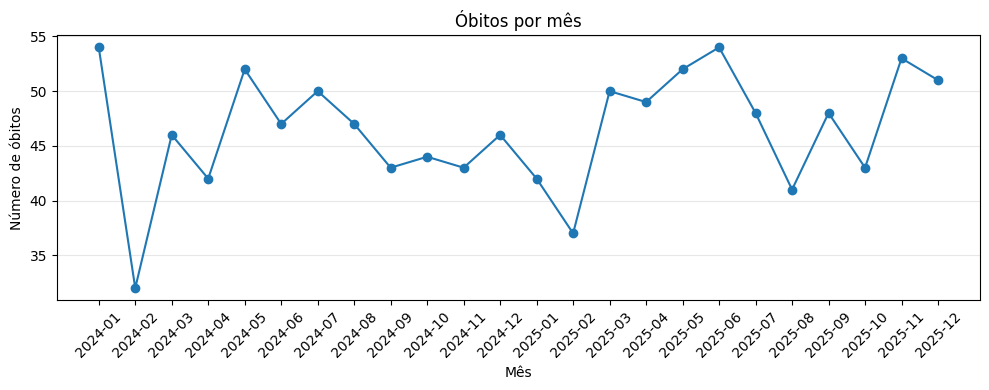

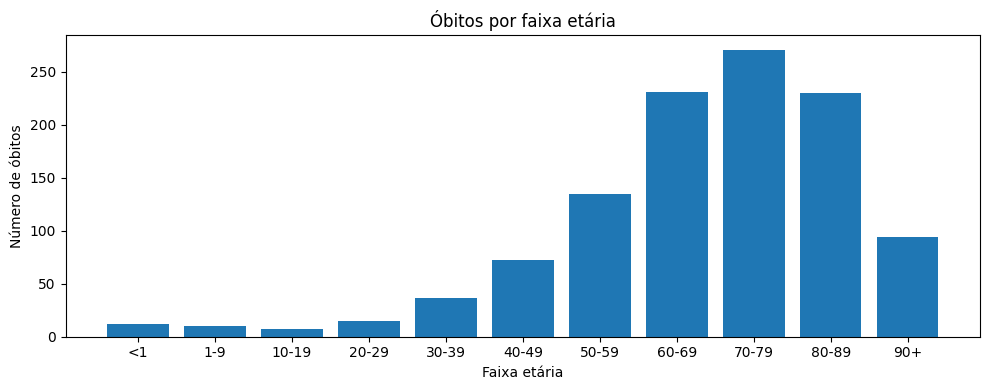

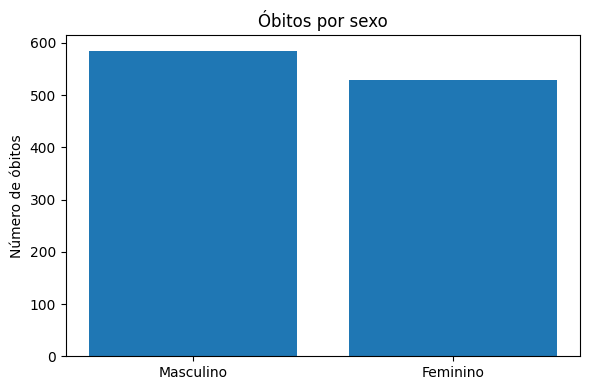

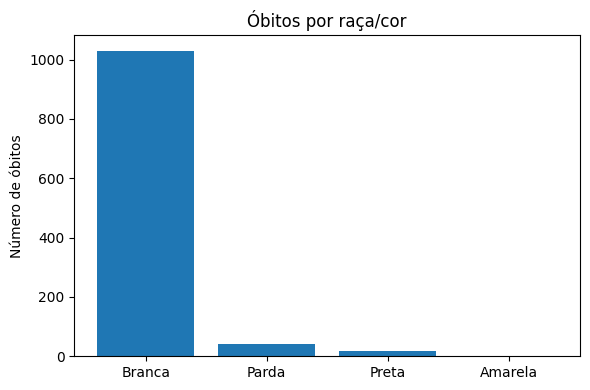

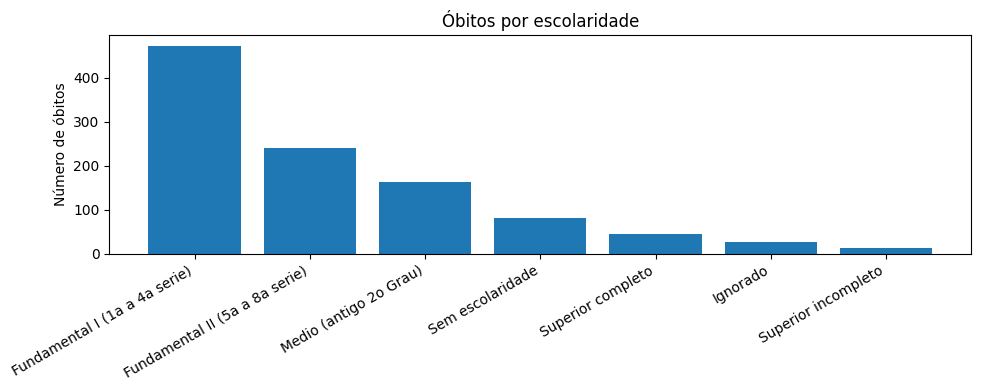

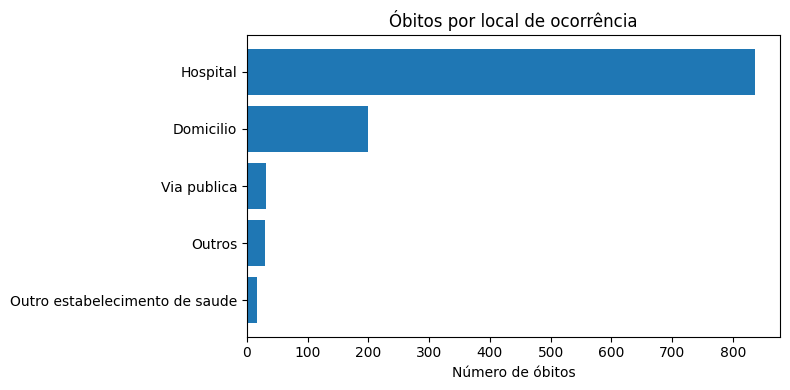

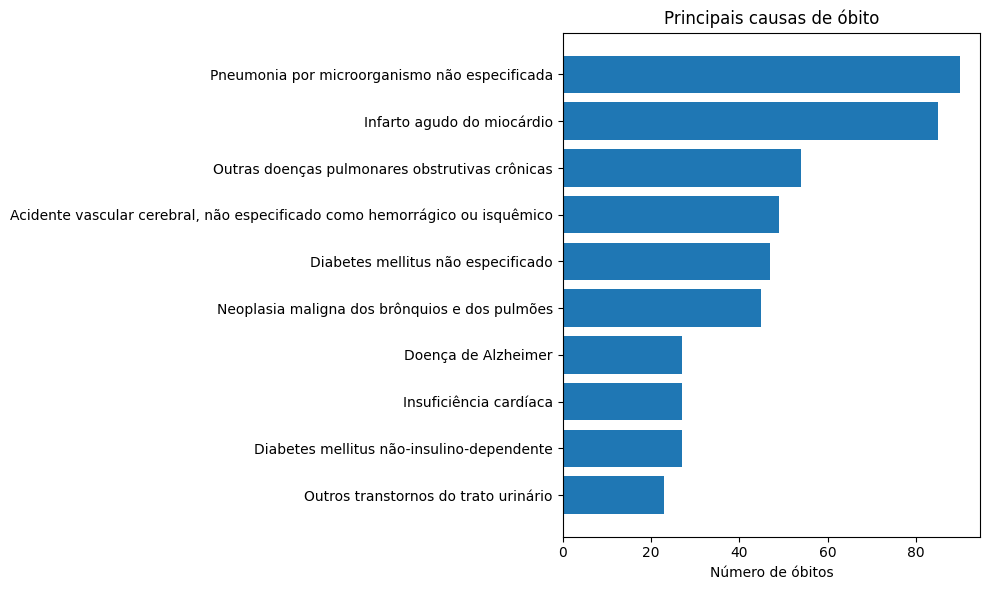

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = df_ararangua

# ---------------------------------------------------------------------------
# Prepara colunas auxiliares
# ---------------------------------------------------------------------------
df["DTOBITO_DT"] = pd.to_datetime(df["DTOBITO"], format="%d/%m/%Y")
df["ANOMES"] = df["DTOBITO_DT"].dt.to_period("M").astype(str)

def idade_em_anos(valor):
    """Converte '60 ano(s)' -> 60. Para meses/horas/minutos, considera menor
    que 1 ano (retorna 0)."""
    if "ano(s)" in str(valor):
        try:
            return int(str(valor).split(" ")[0])
        except ValueError:
            return None
    return 0

df["IDADE_ANOS"] = df["IDADE"].apply(idade_em_anos)

faixas = [0, 1, 10, 20, 30, 40, 50, 60, 70, 80, 90, 200]
rotulos_faixas = ["<1", "1-9", "10-19", "20-29", "30-39", "40-49",
                   "50-59", "60-69", "70-79", "80-89", "90+"]
df["FAIXA_ETARIA"] = pd.cut(df["IDADE_ANOS"], bins=faixas, labels=rotulos_faixas, right=False)

obitos_por_mes = df.groupby("ANOMES").size()

print(f"Total de óbitos: {len(df)}")

plt.figure(figsize=(10, 4))
plt.plot(obitos_por_mes.index, obitos_por_mes.values, marker="o")
plt.title("Óbitos por mês")
plt.xlabel("Mês")
plt.ylabel("Número de óbitos")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

obitos_por_faixa = df["FAIXA_ETARIA"].value_counts().reindex(rotulos_faixas)

plt.figure(figsize=(10, 4))
plt.bar(obitos_por_faixa.index.astype(str), obitos_por_faixa.values)
plt.title("Óbitos por faixa etária")
plt.xlabel("Faixa etária")
plt.ylabel("Número de óbitos")
plt.tight_layout()
plt.show()

obitos_por_sexo = df["SEXO"].value_counts()

plt.figure(figsize=(6, 4))
plt.bar(obitos_por_sexo.index, obitos_por_sexo.values)
plt.title("Óbitos por sexo")
plt.ylabel("Número de óbitos")
plt.tight_layout()
plt.show()

obitos_por_raca = df["RACACOR"].value_counts()

plt.figure(figsize=(6, 4))
plt.bar(obitos_por_raca.index, obitos_por_raca.values)
plt.title("Óbitos por raça/cor")
plt.ylabel("Número de óbitos")
plt.tight_layout()
plt.show()

obitos_por_esc = df["ESC2010"].value_counts()

plt.figure(figsize=(10, 4))
plt.bar(obitos_por_esc.index, obitos_por_esc.values)
plt.title("Óbitos por escolaridade")
plt.ylabel("Número de óbitos")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

obitos_por_local = df["LOCOCOR"].value_counts()

plt.figure(figsize=(8, 4))
plt.barh(obitos_por_local.index, obitos_por_local.values)
plt.title("Óbitos por local de ocorrência")
plt.xlabel("Número de óbitos")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

top_causas = df["CAUSABAS_DESC"].value_counts().head(10)

plt.figure(figsize=(10, 6))
plt.barh(top_causas.index, top_causas.values)
plt.title("Principais causas de óbito")
plt.xlabel("Número de óbitos")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()